# failed-bank-docai: walkthrough

When a bank fails, someone has to turn its loan files into numbers people can trust, fast. This notebook walks
through what this project measured, using only files committed to the repo (plus public FDIC data), so it runs
without any cloud account.

*Independent personal research project. Loan files are synthetic; the FDIC data and the agreements are public.*

In [1]:
import json, sys, collections
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
SYN = ROOT / "samples" / "synthetic"
pd.set_option("display.max_colwidth", 80)

## 1. Context: bank failures since 1934 (public FDIC data)

The 2008–2012 wave (mortgage bubble) and 2023 (Silicon Valley Bank, Signature, First Republic). The data is
downloaded on first run if it isn't cached.

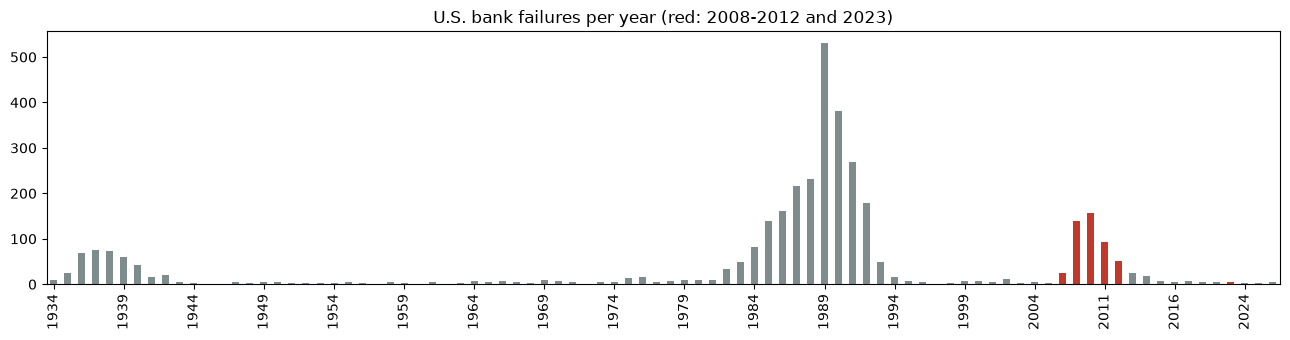

2008-2012: 465 | 1993-2007: 123


In [2]:
import fdic_sources as fs
path = fs.PUBLIC / "failures.json"
if not path.exists():
    fs.fetch_failures(fs._session())
fails = pd.DataFrame(json.loads(path.read_text()))
fails = fails[fails["RESTYPE"] == "FAILURE"]
by_year = fails.groupby(fails["FAILYR"].astype(int)).size()
ax = by_year.plot(kind="bar", figsize=(13, 3.5), color=["#c0392b" if 2008 <= y <= 2012 or y == 2023 else "#7f8c8d" for y in by_year.index])
ax.set_xticks(range(0, len(by_year), 5)); ax.set_xticklabels(by_year.index[::5])
ax.set_title("U.S. bank failures per year (red: 2008-2012 and 2023)"); ax.set_xlabel(""); plt.tight_layout(); plt.show()
print("2008-2012:", by_year.loc[2008:2012].sum(), "| 1993-2007:", by_year.loc[1993:2007].sum())

## 2. The synthetic loan files

Every fictional bank copies a real failed bank's loan mix and has its own layout, wording, formats and note style.
Validation, test and holdout banks use styles never seen in training.

In [3]:
idx = pd.read_csv(SYN / "index.csv")
summary = idx.groupby("split").agg(banks=("bank_id", "nunique"), loan_files=("loan_id", "count"), pages=("pages", "sum"))
summary.loc[["train", "train_aug", "train_plain", "train_hard", "val", "test", "holdout", "holdout2"]]

,banks,loan_files,pages
split,,,
train,3,75,478
train_aug,20,240,1541
train_plain,20,240,1527
train_hard,3,30,239
val,1,25,170
test,2,50,330
holdout,1,25,154
holdout2,1,25,186


In [4]:
label = json.loads((SYN / "labels" / "B5-0002.json").read_text())
print("documents:", [(d["doc_type"], d["page_from"], d["scanned"]) for d in label["documents"]])
print("fields:", {k: label["fields"][k] for k in ["original_principal", "note_rate_pct", "maturity_date", "current_upb"]})
print("planted flags:", label["flags"][:2])

documents: [('promissory_note', 1, False), ('security_instrument', 2, True), ('appraisal_1004', 3, False), ('credit_memo', 4, True), ('servicing_history', 5, False), ('servicer_comments', 6, False)]
fields: {'original_principal': 1744000.0, 'note_rate_pct': 7.625, 'maturity_date': '2009-11-11', 'current_upb': 1744000}
planted flags: [{'flag': 'draw_without_inspection', 'doc_type': 'credit_memo', 'quote': 'Funds were disbursed for the latest draw prior to inspector verification.'}]


## 3. U1: extraction on banks the model never saw

`correct` = matches the planted answer; `wrong` = a value was returned but it's wrong (dangerous);
`missing` = nothing returned (safe: a person fills it in).

In [5]:
def summary(method):
    df = pd.read_csv(SYN / "eval" / f"{method}.csv")
    g = df.groupby("split")["outcome"].value_counts().unstack(fill_value=0)
    g["recall"] = g["correct"] / g.sum(axis=1)
    g["method"] = method
    return g.reset_index()

table = pd.concat([summary(m) for m in ["rules", "fbd-neural-v1", "fbd-neural-v2", "fbd-neural-v3"]])
table = table[table["split"].isin(["val", "test", "holdout", "holdout2"])]
pivot = table.pivot(index="method", columns="split", values="recall").reindex(columns=["val", "test", "holdout", "holdout2"])
pivot.style.format("{:.1%}", na_rep="—")

split,val,test,holdout,holdout2
method,,,,
fbd-neural-v1,99.5%,86.9%,100.0%,87.6%
fbd-neural-v2,72.6%,89.7%,—,—
fbd-neural-v3,96.4%,99.7%,98.5%,99.5%
rules,0.0%,0.0%,0.0%,0.0%


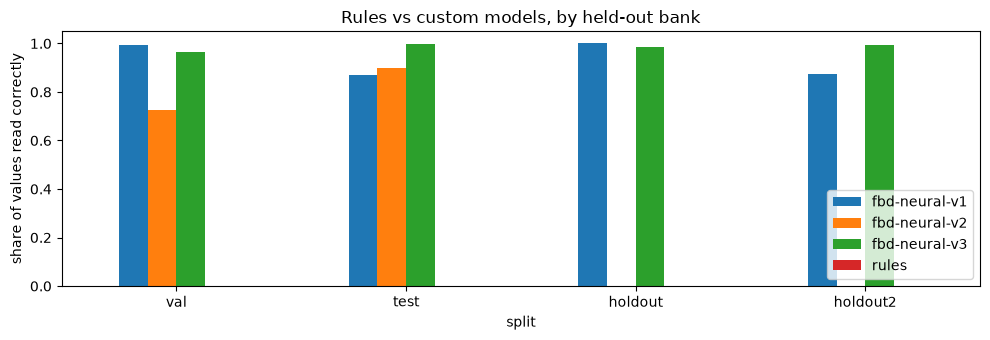

In [6]:
ax = pivot.T.plot(kind="bar", figsize=(10, 3.5), rot=0)
ax.set_ylabel("share of values read correctly"); ax.set_ylim(0, 1.05); ax.set_title("Rules vs custom models, by held-out bank")
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

**Routing:** a value is auto-accepted only if the model is confident, it passes the validity and plausibility
rules, and it agrees with the bank's data-room schedule. Everything else goes to a person. The number that matters
is the *silent error*: wrong and auto-accepted.

In [7]:
import route
rows = route.load("fbd-neural-v3")
val = [r for r in rows if r["split"] == "val"]
cut = route.choose_cutoff(val, 0.02, True)
out = []
for split in ["val", "test", "holdout", "holdout2"]:
    m = route.apply([r for r in rows if r["split"] == split], cut, True)
    out.append({"bank set": split, "values": m["n"], "sent to a person": f"{m['review_rate']:.1%}", "silent errors": m["silent"]})
pd.DataFrame(out)

,bank set,values,sent to a person,silent errors
0,val,197,11.7%,0
1,test,388,2.3%,0
2,holdout,194,1.5%,0
3,holdout2,193,1.6%,0


## 4. U2: risk flags from notes, letters and credit memos

Precise methods are never wrong but miss half the flags at a new bank; the LLM finds every flag but raises false
alarms. The hybrid accepts what both agree on and sends the rest to a person.

In [8]:
tf = json.loads((SYN / "eval" / "text_flags.json").read_text())
rows = []
for split in ["val", "test"]:
    for m in ["keywords", "tfidf", "llm"]:
        a = tf[split][m]["ALL"]
        rows.append({"split": split, "method": m, "precision": a["precision"], "recall": a["recall"]})
    h = tf[split]["hybrid"]
    rows.append({"split": split, "method": "hybrid (auto part)", "precision": h["auto_precision"], "recall": h["recall_after_review"]})
pd.DataFrame(rows).style.format({"precision": "{:.0%}", "recall": "{:.0%}"})

,split,method,precision,recall
0,val,keywords,100%,68%
1,val,tfidf,100%,58%
2,val,llm,79%,100%
3,val,hybrid (auto part),100%,100%
4,test,keywords,100%,45%
5,test,tfidf,100%,47%
6,test,llm,88%,100%
7,test,hybrid (auto part),100%,100%


## 5. U3: terms from 22 real purchase-and-assumption agreements

Checked against the FDIC's public bid summaries. Only ~3% of the agreements' pages were read.

In [9]:
pa = pd.read_csv(SYN / "eval" / "pa_terms.csv")
pa = pa[pa["outcome"] != "no_truth"]
res = pa.groupby(["field", "method"])["outcome"].value_counts().unstack(fill_value=0)
res["correct / total"] = res["correct"].astype(str) + " / " + res.sum(axis=1).astype(str)
res[["correct / total", "wrong"]].unstack("method")

outcome                    correct / total          wrong      
method                                 llm    regex   llm regex
field                                                          
asset_premium_discount_usd         16 / 20  11 / 19     0     0
buyer                              22 / 22   1 / 22     0     1
commercial_loss_share_pct          16 / 21   8 / 21     0     0
deposit_premium_pct                18 / 21  15 / 21     0     1
effective_date                     22 / 22   0 / 22     0     0
loss_share                         17 / 22  18 / 22     0     4
sf_loss_share_pct                  18 / 21  10 / 21     0     0

## Takeaways

1. Rules written from familiar banks find nothing at a new bank; a model trained on varied banks reads 96–99.7%.
2. How you augment matters: random omissions and decoy numbers made the model worse.
3. Every safety check was found by a held-out bank breaking something, so new banks start at full review.
4. With confidence + rules + reconciliation, every bank tested ended with zero silent errors.
5. On real agreements, the LLM with verbatim-quote checks made no wrong readings; its misses were blanks.